# Algoritmo de Boosting y Gradient Boosting con el dataset Iris

Te han contratado como analista de datos para desarrollar un modelo de clasificación con el data set iris. El objetivo es aplicar distintos algoritmos de boosting y gradient boosting para predecir la especie de una flor a partir de sus características.

1. Carga y exploración de datos
2. Aplicación de modelos de AdaBoost, Gradient Boosting y Random Forest
3. Evaluación y comparación de resultados
4. Discusión sobre el impacto de los hiperparámetros y la aplicabilidad de cada algoritmo

## 1. Carga y exploración inicial de datos

Cargaremos el dataset iris usando sklearn, lo convertiremos en un DataFrame de pandas y realizaremos una exploración inicial.

In [17]:
# Importar librerías necesarias
import pandas as pd
import numpy as np
from sklearn.datasets import load_iris

# Cargar el dataset iris
datos_iris = load_iris()
df_iris = pd.DataFrame(datos_iris.data, columns=datos_iris.feature_names)
df_iris['target'] = datos_iris.target

# Exploración inicial
display(df_iris.head())
print('Shape:', df_iris.shape)
display(df_iris.describe())
print('Distribución de clases:')
display(df_iris['target'].value_counts())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


Shape: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


Distribución de clases:


target
0    50
1    50
2    50
Name: count, dtype: int64

## 2. Preparación de los datos

Seleccionamos las variables predictoras y la variable objetivo. Revisamos si hay valores nulos y si es necesario realizar codificación.

In [18]:
# Selección de variables predictoras y objetivo
X = df_iris.drop('target', axis=1)
y = df_iris['target']

# Revisar valores nulos
display(X.isnull().sum())
display(y.isnull().sum())

# En el dataset iris no hay variables categóricas ni valores nulos, por lo que no es necesario codificar ni imputar.

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

np.int64(0)

## 3. División de datos en entrenamiento y prueba

Dividimos el dataset en conjuntos de entrenamiento y prueba usando train_test_split.

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

print('Tamaño de entrenamiento:', X_train.shape)
print('Tamaño de prueba:', X_test.shape)

Tamaño de entrenamiento: (105, 4)
Tamaño de prueba: (45, 4)


## 4. Normalización de los datos

Aplicamos StandardScaler para normalizar las variables predictoras.

In [20]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Media de entrenamiento (después de escalar):', X_train_scaled.mean(axis=0))
print('Desviación estándar de entrenamiento:', X_train_scaled.std(axis=0))

Media de entrenamiento (después de escalar): [ 2.38327876e-15 -1.12145742e-15 -1.37456184e-16 -6.97854473e-17]
Desviación estándar de entrenamiento: [1. 1. 1. 1.]


## 5. Modelo AdaBoost: entrenamiento, predicción y análisis de n_estimators

Entrenamos un AdaBoostClassifier, probamos diferentes valores de n_estimators y analizamos el impacto en el desempeño.

n_estimators=10 -> accuracy: 0.9111
n_estimators=30 -> accuracy: 0.9333
n_estimators=50 -> accuracy: 0.9333
n_estimators=100 -> accuracy: 0.9333


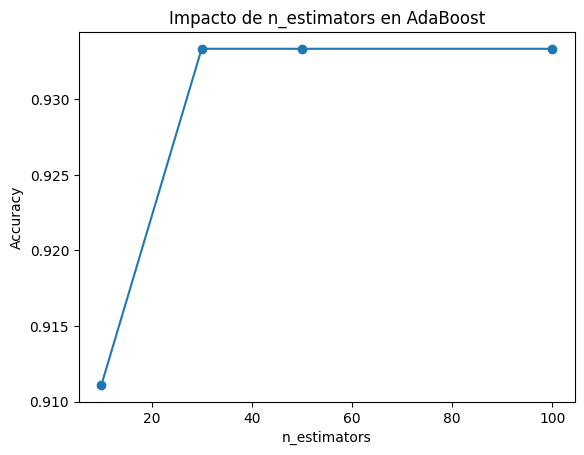

In [21]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt

n_estimators_list = [10, 30, 50, 100]
ada_accuracies = []

for n in n_estimators_list:
    ada = AdaBoostClassifier(n_estimators=n, random_state=42)
    ada.fit(X_train_scaled, y_train)
    y_pred_ada = ada.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred_ada)
    ada_accuracies.append(acc)
    print(f'n_estimators={n} -> accuracy: {acc:.4f}')

plt.plot(n_estimators_list, ada_accuracies, marker='o')
plt.xlabel('n_estimators')
plt.ylabel('Accuracy')
plt.title('Impacto de n_estimators en AdaBoost')
plt.show()

# Guardar el mejor modelo para comparación posterior
best_ada = AdaBoostClassifier(n_estimators=n_estimators_list[np.argmax(ada_accuracies)], random_state=42)
best_ada.fit(X_train_scaled, y_train)
y_pred_ada_best = best_ada.predict(X_test_scaled)

## 6. Modelo Gradient Boosting: entrenamiento, ajuste de hiperparámetros y evaluación

Entrenamos un GradientBoostingClassifier, ajustamos hiperparámetros como n_estimators, learning_rate y max_depth, y evaluamos el desempeño.

In [22]:
from sklearn.ensemble import GradientBoostingClassifier

# Prueba de diferentes hiperparámetros
gb_params = {
    'n_estimators': [30, 50, 100],
    'learning_rate': [0.05, 0.1, 0.2],
    'max_depth': [1, 2, 3]
}

best_acc = 0
best_gb = None
best_params = None
for n in gb_params['n_estimators']:
    for lr in gb_params['learning_rate']:
        for md in gb_params['max_depth']:
            gb = GradientBoostingClassifier(n_estimators=n, learning_rate=lr, max_depth=md, random_state=42)
            gb.fit(X_train_scaled, y_train)
            y_pred_gb = gb.predict(X_test_scaled)
            acc = accuracy_score(y_test, y_pred_gb)
            print(f'n_estimators={n}, learning_rate={lr}, max_depth={md} -> accuracy: {acc:.4f}')
            if acc > best_acc:
                best_acc = acc
                best_gb = gb
                best_params = (n, lr, md)

y_pred_gb_best = best_gb.predict(X_test_scaled)
print(f'Mejor combinación: n_estimators={best_params[0]}, learning_rate={best_params[1]}, max_depth={best_params[2]} -> accuracy: {best_acc:.4f}')

n_estimators=30, learning_rate=0.05, max_depth=1 -> accuracy: 0.9111
n_estimators=30, learning_rate=0.05, max_depth=2 -> accuracy: 0.9333
n_estimators=30, learning_rate=0.05, max_depth=3 -> accuracy: 0.9778
n_estimators=30, learning_rate=0.1, max_depth=1 -> accuracy: 0.9111
n_estimators=30, learning_rate=0.1, max_depth=2 -> accuracy: 0.9333
n_estimators=30, learning_rate=0.1, max_depth=3 -> accuracy: 0.9556
n_estimators=30, learning_rate=0.2, max_depth=1 -> accuracy: 0.8889
n_estimators=30, learning_rate=0.2, max_depth=2 -> accuracy: 0.9333
n_estimators=30, learning_rate=0.2, max_depth=3 -> accuracy: 0.9556
n_estimators=50, learning_rate=0.05, max_depth=1 -> accuracy: 0.9556
n_estimators=50, learning_rate=0.05, max_depth=2 -> accuracy: 0.9333
n_estimators=50, learning_rate=0.05, max_depth=3 -> accuracy: 0.9778
n_estimators=50, learning_rate=0.1, max_depth=1 -> accuracy: 0.9333
n_estimators=50, learning_rate=0.1, max_depth=2 -> accuracy: 0.9333
n_estimators=50, learning_rate=0.1, max_de

## 7. Modelo Random Forest: entrenamiento y comparación

Entrenamos un RandomForestClassifier como referencia (bagging), realizamos predicciones y comparamos su rendimiento con los modelos de boosting.

In [23]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_scaled, y_train)
y_pred_rf = rf.predict(X_test_scaled)
rf_acc = accuracy_score(y_test, y_pred_rf)
print(f'Random Forest accuracy: {rf_acc:.4f}')

Random Forest accuracy: 0.8889


## 8. Evaluación de modelos: accuracy y matriz de confusión

Calculamos y mostramos la accuracy y la matriz de confusión para cada modelo.

AdaBoost (mejor n_estimators):
Accuracy: 0.9333333333333333


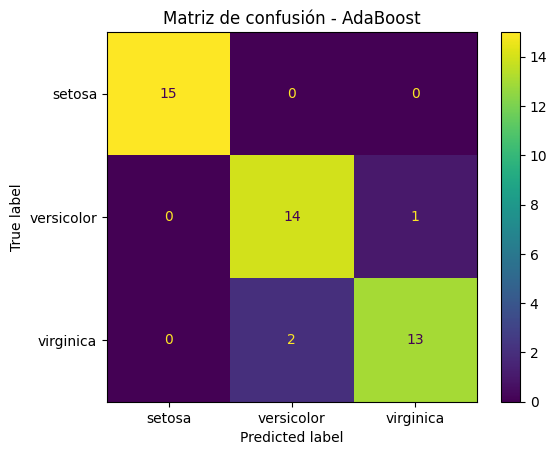

Gradient Boosting (mejores hiperparámetros):
Accuracy: 0.9777777777777777


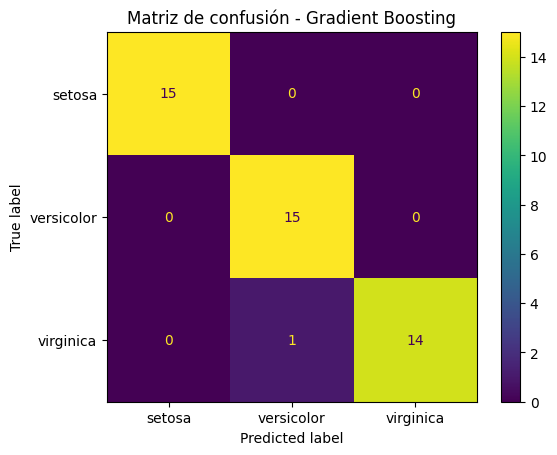

Random Forest:
Accuracy: 0.8888888888888888


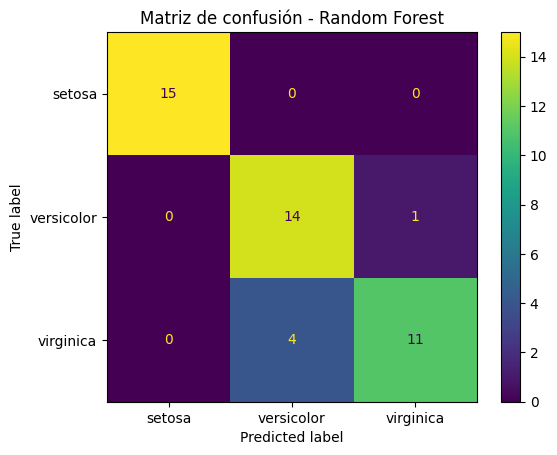

In [24]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# AdaBoost
print('AdaBoost (mejor n_estimators):')
print('Accuracy:', accuracy_score(y_test, y_pred_ada_best))
ConfusionMatrixDisplay.from_estimator(best_ada, X_test_scaled, y_test, display_labels=datos_iris.target_names)
plt.title('Matriz de confusión - AdaBoost')
plt.show()

# Gradient Boosting
print('Gradient Boosting (mejores hiperparámetros):')
print('Accuracy:', accuracy_score(y_test, y_pred_gb_best))
ConfusionMatrixDisplay.from_estimator(best_gb, X_test_scaled, y_test, display_labels=datos_iris.target_names)
plt.title('Matriz de confusión - Gradient Boosting')
plt.show()

# Random Forest
print('Random Forest:')
print('Accuracy:', rf_acc)
ConfusionMatrixDisplay.from_estimator(rf, X_test_scaled, y_test, display_labels=datos_iris.target_names)
plt.title('Matriz de confusión - Random Forest')
plt.show()

## 9. Análisis comparativo de resultados y discusión de hiperparámetros

- **Comparación de modelos:**
  - ¿Cuál modelo tuvo mejor desempeño y por qué?
- **Impacto de los hiperparámetros:**
  - ¿Cómo afectaron los hiperparámetros en cada modelo?
- **Aplicabilidad:**
  - ¿En qué casos sería recomendable utilizar cada algoritmo?

> Escribe aquí tu análisis y conclusiones.